# MethaneScope AI — Lesson 2.2
## Scientific quality control and ingestion of **real NASA EMIT** plume data

**Purpose:** Inspect and validate an already downloaded **EMITL2BCH4PLM.002** plume granule. Produce scientifically labelled, reproducible, machine-readable records that can later populate PostgreSQL/PostGIS.

**Prerequisite:** Complete Lesson 2.1, including the actual NASA download. This notebook does not fabricate data or silently substitute the earlier synthetic file.

**Source:** NASA LP DAAC, [EMITL2BCH4PLM.002](https://doi.org/10.5067/EMIT/EMITL2BCH4PLM.002); [EMIT L2B GHG User Guide](https://lpdaac.usgs.gov/documents/2250/EMIT_L2B_GHG_User_Guide_V2.pdf).

> **Important science:** CH₄ plume enhancement is reported in **ppm m**, *not* kg/h. A plume GeoJSON may contain a separately derived emission-rate estimate (sometimes `N/A`), which must not be recalculated from the raster without a validated method. Negative retrieved enhancement values may occur due to measurement/retrieval errors; **do not clip to zero** when auditing.


### Cell 1 — Imports and locate the project root

Your earlier notebook saved data under `data/raw/nasa_emit`. This cell looks for that directory whether Jupyter's working directory is the project root or a `notebooks` subdirectory.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio
from rasterio.plot import plotting_extent
from rasterio.features import geometry_mask
from rasterio.warp import transform as reproject_points
import geopandas as gpd

candidates = [Path.cwd(), *list(Path.cwd().parents)[:3]]
ROOT = next((p for p in candidates if (p / "data" / "raw" / "nasa_emit").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError(
        "Could not find data/raw/nasa_emit. First run Lesson 2.1 through the "
        "NASA Earthdata download cell, and confirm the data folder exists."
    )
RAW = ROOT / "data" / "raw" / "nasa_emit"
OUT = ROOT / "outputs" / "emit_qa"
OUT.mkdir(parents=True, exist_ok=True)
print("Project root:", ROOT)
print("NASA raw folder:", RAW)
print("Quality-control outputs:", OUT)


Project root: C:\Users\SOOQ ELASER\OneDrive\Desktop\RemoteSensing\MethaneScope
NASA raw folder: C:\Users\SOOQ ELASER\OneDrive\Desktop\RemoteSensing\MethaneScope\data\raw\nasa_emit
Quality-control outputs: C:\Users\SOOQ ELASER\OneDrive\Desktop\RemoteSensing\MethaneScope\outputs\emit_qa


### Cell 2 — Inventory files and select one NASA plume granule

Do not mix a GeoJSON from one plume with the TIFF from another. If several files were downloaded, this cell selects a matching GeoJSON using a shared acquisition timestamp (when present). Review the chosen names before proceeding.

In [2]:
rasters = sorted([p for p in RAW.rglob("*") if p.is_file() and p.suffix.lower() in {".tif", ".tiff"}])
vectors = sorted([p for p in RAW.rglob("*") if p.is_file() and p.suffix.lower() in {".geojson", ".json"}])
print("NASA GeoTIFFs:", [p.name for p in rasters])
print("NASA GeoJSONs:", [p.name for p in vectors])

if not rasters:
    raise FileNotFoundError(
        f"No NASA GeoTIFF found in {RAW}. Complete the download in Lesson 2.1 first."
    )

raster_path = rasters[0]  # First raster, sorted by filename (change if you want another plume)

def acquisition_token(filename):
    m = re.search(r"\d{8}T\d{6}", filename)
    return m.group(0) if m else None

raster_token = acquisition_token(raster_path.name)
if not vectors:
    vector_path = None
elif len(vectors) == 1:
    vector_path = vectors[0]
else:
    matching = [p for p in vectors if raster_token and acquisition_token(p.name) == raster_token]
    if len(matching) != 1:
        raise ValueError("Multiple GeoJSONs and no unique timestamp match. Select vector_path manually after examining filenames.")
    vector_path = matching[0]

if vector_path is not None:
    vector_token = acquisition_token(vector_path.name)
    if raster_token and vector_token and raster_token != vector_token:
        raise ValueError("GeoTIFF and GeoJSON acquisition timestamps differ; do not pair them.")

print("SELECTED RASTER:", raster_path.name)
print("SELECTED GEOJSON:", vector_path.name if vector_path else "Not available")
print("Only continue if these describe the same granule.")


NASA GeoTIFFs: ['EMIT_L2B_CH4PLM_002_20220810T064957_000485.tif']
NASA GeoJSONs: ['EMIT_L2B_CH4PLMMETA_002_20220810T064957_000485.json']
SELECTED RASTER: EMIT_L2B_CH4PLM_002_20220810T064957_000485.tif
SELECTED GEOJSON: EMIT_L2B_CH4PLMMETA_002_20220810T064957_000485.json
Only continue if these describe the same granule.


### Cell 3 — Open the scientific raster and read its native metadata

We will mask fill/nodata values, preserve original valid enhancements (including negative values), and record the **native CRS** and geotransform. We do not resample or alter the original file.

In [3]:
issues = []
with rasterio.open(raster_path) as src:
    count = src.count
    width, height = src.width, src.height
    crs = src.crs
    bounds = src.bounds
    transform = src.transform
    nodata = src.nodata
    file_tags = src.tags()
    band_tags = src.tags(1) if count else {}
    band_descriptions = src.descriptions
    image = np.ma.masked_invalid(src.read(1, masked=True).astype("float64")) if count else None
    extent = plotting_extent(src)
    driver = src.driver

if count != 1:
    issues.append(f"Expected the NASA EMIT PLM product to have one band; found {count}. Inspect before interpreting band 1.")
if crs is None:
    issues.append("CRITICAL: Raster CRS is missing; geographical coordinate conversion is unsafe.")
if image is None or image.count() == 0:
    raise ValueError("No usable finite pixels in raster band 1. Inspect nodata, masks, and source product.")

pixel_mask = np.ma.getmaskarray(image)
valid = image.compressed()
print("Dimensions:", width, "x", height, "| bands:", count, "| driver:", driver)
print("CRS:", crs, "| nodata:", nodata, "| masked fraction:", round(pixel_mask.mean(), 5))
print("Band descriptions:", band_descriptions)
print("Raster tags:", file_tags)
print("Band 1 tags:", band_tags)
print("Raw, finite pixel values are retained, including negatives.")


Dimensions: 256 x 245 | bands: 1 | driver: GTiff
CRS: EPSG:4326 | nodata: -9999.0 | masked fraction: 0.96864
Band descriptions: (None,)
Raster tags: {'Conventions': 'CF-1.13', 'creator_name': 'Jet Propulsion Laboratory/California Institute of Technology', 'creator_url': 'https://earth.jpl.nasa.gov/emit/', 'DAAC Scene Names': "['EMIT_L2B_CH4ENH_V002_20220810T064957_2222205_033']", 'date_created': '2026-02-03T08:48:06Z', 'identifier_product_doi_authority': 'https://doi.org', 'institution': 'NASA Jet Propulsion Laboratory/California Institute of Technology', 'instrument': 'EMIT', 'keywords': 'Imaging Spectroscopy, minerals, EMIT, dust, radiative forcing', 'keywords_vocabulary': 'NASA Global Change Master Directory (GCMD) Science Keywords', 'Latitude of max concentration': '31.12789', 'license': 'https://www.earthdata.nasa.gov/engage/open-data-services-software-policies/data-use-guidance', 'Longitude of max concentration': '35.20281', 'Max Plume Concentration (ppm m)': '3038.0', 'naming_au

### Cell 4 — Summary statistics and the maximum **observed enhancement pixel**

The highest pixel in a plume raster is **not automatically the emission source**. Nor is the maximum plume enhancement an emission rate.

In [4]:
row, col = np.unravel_index(np.ma.filled(image, -np.inf).argmax(), image.shape)
with rasterio.open(raster_path) as src:
    x_max, y_max = rasterio.transform.xy(src.transform, int(row), int(col), offset="center")

lon_max = lat_max = None
if crs is not None:
    lon, lat = reproject_points(crs, "EPSG:4326", [x_max], [y_max])
    lon_max, lat_max = float(lon[0]), float(lat[0])

stats = {
    "valid_pixel_count": int(valid.size),
    "total_pixel_count": int(width * height),
    "valid_fraction": float(valid.size / (width * height)),
    "minimum_ppm_m": float(valid.min()),
    "p05_ppm_m": float(np.percentile(valid, 5)),
    "median_ppm_m": float(np.median(valid)),
    "p95_ppm_m": float(np.percentile(valid, 95)),
    "maximum_ppm_m": float(valid.max()),
    "mean_ppm_m": float(valid.mean()),
    "maximum_pixel_row": int(row),
    "maximum_pixel_col": int(col),
    "maximum_pixel_x_native_crs": float(x_max),
    "maximum_pixel_y_native_crs": float(y_max),
    "maximum_pixel_lon_wgs84": lon_max,
    "maximum_pixel_lat_wgs84": lat_max,
}
print(pd.Series(stats).to_string())
print("\nWARNING: The maximum pixel coordinate is NOT independently verified as the emission source.")


valid_pixel_count              1967.000000
total_pixel_count             62720.000000
valid_fraction                    0.031362
minimum_ppm_m                 -1005.109863
p05_ppm_m                      -356.545236
median_ppm_m                    370.634338
p95_ppm_m                      1528.792371
maximum_ppm_m                  3037.613770
mean_ppm_m                      461.146203
maximum_pixel_row               114.000000
maximum_pixel_col               119.000000
maximum_pixel_x_native_crs       35.202815
maximum_pixel_y_native_crs       31.127890
maximum_pixel_lon_wgs84          35.202815
maximum_pixel_lat_wgs84          31.127890



### Cell 5 — Inspect GeoJSON attributes and geometry

NASA describes the Version 2 plume metadata as including source-scene information, maximum-enhancement position, and where estimable an **emission-rate estimate and uncertainty**. Do not assume that every property exists or has a numeric value. This code displays all present fields without inventing defaults.

In [5]:
plumes = None
geojson_properties = []
if vector_path is None:
    issues.append("GeoJSON metadata file unavailable: no plume geometry or vector attributes were audited.")
    print("No GeoJSON found. Continue with raster QA only.")
else:
    with open(vector_path, encoding="utf-8") as fh:
        raw_geojson = json.load(fh)
    features = raw_geojson.get("features", []) if raw_geojson.get("type") == "FeatureCollection" else []
    geojson_properties = [f.get("properties", {}) for f in features]
    print("GeoJSON feature count:", len(features))
    if not features:
        issues.append("GeoJSON has no standard FeatureCollection features.")
    for i, props in enumerate(geojson_properties[:3]):
        print(f"\nFEATURE {i+1}: scientific properties present in source metadata")
        for key, value in props.items():
            print(f"  {key}: {str(value)[:300]}")
    plumes = gpd.read_file(vector_path)
    print("\nGeometry types:", plumes.geometry.geom_type.value_counts(dropna=False).to_dict())
    print("Vector CRS:", plumes.crs)
    if plumes.crs is None:
        issues.append("CRITICAL: GeoJSON CRS not identified; spatial overlay cannot be independently validated.")
    if not plumes.geometry.is_valid.all():
        issues.append("Some GeoJSON geometries are invalid; investigate before computing spatial intersections.")


GeoJSON feature count: 1

FEATURE 1: scientific properties present in source metadata
  Plume ID: CH4_PlumeComplex-485
  Orbit: 2222205
  DCID: 1344041727
  UTC Time Observed: 2022-08-10T06:49:57Z
  Max Plume Concentration (ppm m): 3038.0
  Latitude of max concentration: 31.12789
  Longitude of max concentration: 35.20281
  Wind Speed (m/s): NA
  Wind Speed Std (m/s): NA
  Wind Speed Source: NA
  Emissions Rate Estimate (kg/hr): NA
  Emissions Rate Estimate Uncertainty (kg/hr): NA
  Fetch Length (m): NA
  DAAC Scene Names: ['EMIT_L2B_CH4ENH_V002_20220810T064957_2222205_033']

Geometry types: {'Polygon': 1}
Vector CRS: EPSG:4326


### Cell 6 — Validate geographic overlay and examine pixels **inside plume polygons**

This step only computes inside-polygon statistics when polygons are present, valid, and transformable to the raster CRS. If the GeoJSON has only points or other geometries, it will skip the polygon test. Statistics are only for the downloaded plume product, not a regional baseline.

In [6]:
inside_stats = None
projected_plumes = None
if plumes is not None and crs is not None and plumes.crs is not None:
    projected_plumes = plumes.to_crs(crs)
    polygons = projected_plumes[
        projected_plumes.geometry.geom_type.isin(["Polygon", "MultiPolygon"])
        & projected_plumes.geometry.is_valid
        & (~projected_plumes.geometry.is_empty)
    ]
    if len(polygons) > 0:
        geoms = [g.__geo_interface__ for g in polygons.geometry]
        inside_mask = geometry_mask(geoms, out_shape=image.shape, transform=transform, invert=True)
        vals_inside = np.asarray(image.data)[inside_mask & (~pixel_mask)]
        vals_inside = vals_inside[np.isfinite(vals_inside)]
        if vals_inside.size:
            inside_stats = {
                "valid_pixels_inside_outline": int(vals_inside.size),
                "mean_ppm_m_inside_outline": float(vals_inside.mean()),
                "median_ppm_m_inside_outline": float(np.median(vals_inside)),
                "maximum_ppm_m_inside_outline": float(vals_inside.max()),
            }
            print(pd.Series(inside_stats).to_string())
        else:
            issues.append("No valid raster pixel centres overlapped the mapped plume outline; investigate georeferencing.")
    else:
        print("No valid polygon outlines available: polygon statistics skipped.")
else:
    print("No verified raster/vector CRS pair: polygon overlap skipped.")


valid_pixels_inside_outline     1967.000000
mean_ppm_m_inside_outline        461.146203
median_ppm_m_inside_outline      370.634338
maximum_ppm_m_inside_outline    3037.613770


### Cell 7 — Display and save the original plume with official geometry (if available)

The display limits are based on the 2nd and 98th percentiles for readability. This modifies **only the colour scale**, not the measurements. The magenta marker shows the maximum valid raster pixel, not a confirmed source.

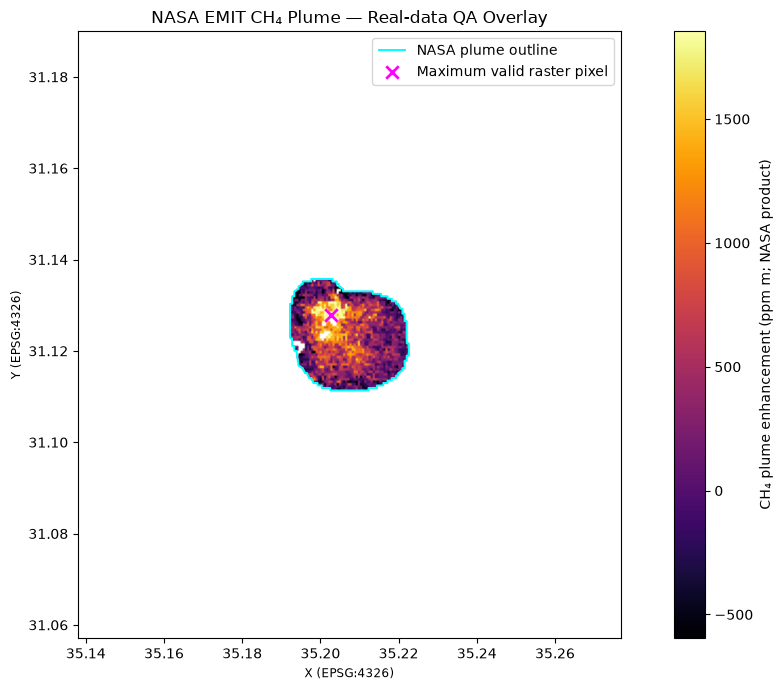

Saved plot: C:\Users\SOOQ ELASER\OneDrive\Desktop\RemoteSensing\MethaneScope\outputs\emit_qa\EMIT_L2B_CH4PLM_002_20220810T064957_000485_qa_overlay.png


In [7]:
vmin, vmax = np.percentile(valid, [2, 98])
if vmin == vmax:
    vmin, vmax = float(valid.min()), float(valid.max())
    if vmin == vmax:
        vmax = vmin + 1e-6

fig, ax = plt.subplots(figsize=(11, 7))
im = ax.imshow(image, origin="upper", extent=extent, cmap="inferno", vmin=vmin, vmax=vmax)
fig.colorbar(im, ax=ax, label="CH₄ plume enhancement (ppm m; NASA product)")
if projected_plumes is not None:
    polys = projected_plumes[projected_plumes.geometry.geom_type.isin(["Polygon", "MultiPolygon"])]
    if not polys.empty:
        polys.boundary.plot(ax=ax, edgecolor="cyan", linewidth=1.4, label="NASA plume outline")
    points = projected_plumes[projected_plumes.geometry.geom_type.isin(["Point", "MultiPoint"])]
    if not points.empty:
        points.plot(ax=ax, color="lime", markersize=40, label="NASA metadata point")
ax.scatter([x_max], [y_max], marker="x", color="magenta", s=80, linewidths=2, label="Maximum valid raster pixel")
ax.set_title("NASA EMIT CH₄ Plume — Real-data QA Overlay")
ax.set_xlabel(f"X ({crs})")
ax.set_ylabel(f"Y ({crs})")
ax.legend(loc="best")
plt.tight_layout()
plot_path = OUT / f"{raster_path.stem}_qa_overlay.png"
fig.savefig(plot_path, dpi=150, bbox_inches="tight")
plt.show()
print("Saved plot:", plot_path)


### Cell 8 — Generate reproducible ingestion identity and data-quality report

SHA-256 identifies this exact raster file content. Re-ingesting the same bytes will give the same ID. This is a **technical duplicate guard**, not a guarantee that two differently processed files are independent observations.

We also record warnings explicitly. *Passing structural checks does not mean the methane retrieval is scientifically validated.*

In [8]:
def sha256_file(path, chunk_size=1024 * 1024):
    digest = hashlib.sha256()
    with open(path, "rb") as fh:
        while chunk := fh.read(chunk_size):
            digest.update(chunk)
    return digest.hexdigest()

raster_hash = sha256_file(raster_path)
vector_hash = sha256_file(vector_path) if vector_path else None
record_id = f"NASA_EMIT_CH4PLM_002_{raster_hash[:20]}"

if stats["valid_fraction"] < 0.01:
    issues.append("Less than 1% of raster pixels are valid; review masks and expected data extent.")
if not np.isfinite(valid).all():
    issues.append("CRITICAL: Non-finite values remained after masking.")

report = {
    "record_id": record_id,
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "provider": "NASA LP DAAC",
    "instrument": "EMIT",
    "dataset_short_name": "EMITL2BCH4PLM",
    "dataset_version": "002 (expected; verify downloaded granule)",
    "dataset_doi": "10.5067/EMIT/EMITL2BCH4PLM.002",
    "enhancement_units": "ppm m (per product documentation)",
    "raster_file": str(raster_path.resolve()),
    "raster_sha256": raster_hash,
    "geojson_file": str(vector_path.resolve()) if vector_path else None,
    "geojson_sha256": vector_hash,
    "raster_crs": str(crs) if crs else None,
    "raster_width": width,
    "raster_height": height,
    "band_count": count,
    "nodata": nodata,
    "geographical_bounds_native_crs": list(map(float, bounds)),
    "statistics": stats,
    "polygon_statistics": inside_stats,
    "geojson_first_feature_properties": geojson_properties[0] if geojson_properties else None,
    "quality_issues": issues,
    "structural_qc": "REVIEW_REQUIRED" if issues else "NO_ISSUES_DETECTED",
    "scientific_validation": "NOT_ESTABLISHED_BY_THIS_NOTEBOOK",
}

# Convert unusual metadata scalar types safely for reporting, leaving source files untouched.
json_path = OUT / f"{raster_path.stem}_qa_report.json"
with open(json_path, "w", encoding="utf-8") as fh:
    json.dump(report, fh, indent=2, default=str)

print("Record:", record_id)
print("Structural QC:", report["structural_qc"])
print("Warnings:", issues or "None from implemented checks")
print("Saved:", json_path)


Record: NASA_EMIT_CH4PLM_002_d3f2251013aa522e98dc
Structural QC: NO_ISSUES_DETECTED
Warnings: None from implemented checks
Saved: C:\Users\SOOQ ELASER\OneDrive\Desktop\RemoteSensing\MethaneScope\outputs\emit_qa\EMIT_L2B_CH4PLM_002_20220810T064957_000485_qa_report.json


### Cell 9 — Export an ingestion-ready tabular record

The CSV keeps the scientific raster summaries, file checksum and file paths. Complex GeoJSON attributes remain in the JSON report. A later lesson will create *typed tables* for plume observations, source associations, metadata and processing history in PostgreSQL/PostGIS.

In [9]:
record = {
    "record_id": record_id,
    "provider": "NASA LP DAAC",
    "product": "EMITL2BCH4PLM.002",
    "raster_sha256": raster_hash,
    "geojson_sha256": vector_hash,
    "raster_file": str(raster_path.relative_to(ROOT)),
    "geojson_file": str(vector_path.relative_to(ROOT)) if vector_path else "",
    "crs": str(crs) if crs else "",
    "valid_pixels": stats["valid_pixel_count"],
    "max_enhancement_ppm_m": stats["maximum_ppm_m"],
    "mean_enhancement_ppm_m": stats["mean_ppm_m"],
    "max_pixel_lon_wgs84": lon_max,
    "max_pixel_lat_wgs84": lat_max,
    "structural_qc": report["structural_qc"],
    "scientific_validation": report["scientific_validation"],
}
records_df = pd.DataFrame([record])
csv_path = OUT / "emit_plume_ingestion_records.csv"
records_df.to_csv(csv_path, index=False)
print(records_df.T.to_string(header=False))
print("\nSaved:", csv_path)


record_id                                            NASA_EMIT_CH4PLM_002_d3f2251013aa522e98dc
provider                                                                          NASA LP DAAC
product                                                                      EMITL2BCH4PLM.002
raster_sha256                 d3f2251013aa522e98dc7e6bb3b55cda048601ec6c9ae8d4912c18bc7b16e2eb
geojson_sha256                1a4d05ec2d4c0797bc45da760091073807040224a245bf5de7a7e2d68013f519
raster_file                  data\raw\nasa_emit\EMIT_L2B_CH4PLM_002_20220810T064957_000485.tif
geojson_file            data\raw\nasa_emit\EMIT_L2B_CH4PLMMETA_002_20220810T064957_000485.json
crs                                                                                  EPSG:4326
valid_pixels                                                                              1967
max_enhancement_ppm_m                                                               3037.61377
mean_enhancement_ppm_m                            

### Cell 10 — Final checkpoint and interpretation

Run the cell below, then share its *output* and the saved plume overlay screenshot.

1. Did the downloaded raster have a valid CRS and one band?
2. How many valid pixels did it contain?
3. What is the maximum **enhancement** value, and in which units?
4. Did NASA provide a plume polygon, an emission-rate estimate, and/or an uncertainty field?
5. Why is the maximum raster pixel **not** necessarily the actual source location?

**What we did not do:** derive a new emission rate, validate the NASA retrieval against ground truth, calculate source persistency, or merge different plumes. Those come in later lessons.

**Next:** Lesson 2.3 — Multi-granule ingestion, deduplication, explicit schema and a small PostgreSQL/PostGIS data model.


In [10]:
print("METHANESCOPE — LESSON 2.2 COMPLETE")
print("Raster:", raster_path.name)
print("GeoJSON:", vector_path.name if vector_path else "Not available")
print("Valid pixels:", stats["valid_pixel_count"])
print("Maximum enhancement (ppm m):", round(stats["maximum_ppm_m"], 3))
print("Structural QC:", report["structural_qc"])
print("Report:", json_path)
print("CSV:", csv_path)
print("Plot:", plot_path)


METHANESCOPE — LESSON 2.2 COMPLETE
Raster: EMIT_L2B_CH4PLM_002_20220810T064957_000485.tif
GeoJSON: EMIT_L2B_CH4PLMMETA_002_20220810T064957_000485.json
Valid pixels: 1967
Maximum enhancement (ppm m): 3037.614
Structural QC: NO_ISSUES_DETECTED
Report: C:\Users\SOOQ ELASER\OneDrive\Desktop\RemoteSensing\MethaneScope\outputs\emit_qa\EMIT_L2B_CH4PLM_002_20220810T064957_000485_qa_report.json
CSV: C:\Users\SOOQ ELASER\OneDrive\Desktop\RemoteSensing\MethaneScope\outputs\emit_qa\emit_plume_ingestion_records.csv
Plot: C:\Users\SOOQ ELASER\OneDrive\Desktop\RemoteSensing\MethaneScope\outputs\emit_qa\EMIT_L2B_CH4PLM_002_20220810T064957_000485_qa_overlay.png
